# **Waste Material Segregation for Improving Waste Management**

## **Objective**

The objective of this project is to implement an effective waste material segregation system using convolutional neural networks (CNNs) that categorises waste into distinct groups. This process enhances recycling efficiency, minimises environmental pollution, and promotes sustainable waste management practices.

The key goals are:

* Accurately classify waste materials into categories like cardboard, glass, paper, and plastic.
* Improve waste segregation efficiency to support recycling and reduce landfill waste.
* Understand the properties of different waste materials to optimise sorting methods for sustainability.

## **Data Understanding**

The Dataset consists of images of some common waste materials.

1. Food Waste
2. Metal
3. Paper
4. Plastic
5. Other
6. Cardboard
7. Glass


**Data Description**

* The dataset consists of multiple folders, each representing a specific class, such as `Cardboard`, `Food_Waste`, and `Metal`.
* Within each folder, there are images of objects that belong to that category.
* However, these items are not further subcategorised. <br> For instance, the `Food_Waste` folder may contain images of items like coffee grounds, teabags, and fruit peels, without explicitly stating that they are actually coffee grounds or teabags.

## **1. Load the data**

Load and unzip the dataset zip file.

**Import Necessary Libraries**

In [1]:
# Recommended versions:

# numpy version: 1.26.4
# pandas version: 2.2.2
# seaborn version: 0.13.2
# matplotlib version: 3.10.0
# PIL version: 11.1.0
# tensorflow version: 2.18.0
# keras version: 3.8.0
# sklearn version: 1.6.1

In [2]:
# Import essential libraries

import os
import glob
import zipfile
import random
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Load the dataset.

In [3]:
# Load and unzip the dataset

from google.colab import drive
drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/data.zip"   # zip kept in Drive
DATA_DIR = "/content/data"                     # unzipped here (fast local disk)
CLASS_NAMES = ["Cardboard", "Food_Waste", "Glass", "Metal", "Other", "Paper", "Plastic"]

if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content")

print("data dir:", DATA_DIR, "| classes:", sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
data dir: /content/data | classes: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']


## **2. Data Preparation** <font color=red> [25 marks] </font><br>


### **2.1 Load and Preprocess Images** <font color=red> [8 marks] </font><br>

Let us create a function to load the images first. We can then directly use this function while loading images of the different categories to load and crop them in a single step.

#### **2.1.1** <font color=red> [3 marks] </font><br>
Create a function to load the images.

In [4]:
# Create a function to load the raw images

def load_image(path, size=None):
    img = Image.open(path).convert("RGB")
    if size is not None:
        img = img.resize(size)
    return np.asarray(img, dtype=np.uint8)

def load_dataset(data_dir, class_names, size=None):
    images, labels = [], []
    for cls in class_names:
        for fp in glob.glob(os.path.join(data_dir, cls, "*.png")):
            images.append(load_image(fp, size=size))
            labels.append(cls)
    return images, labels

#### **2.1.2** <font color=red> [5 marks] </font><br>
Load images and labels.

Load the images from the dataset directory. Labels of images are present in the subdirectories.

Verify if the images and labels are loaded correctly.

In [5]:
# Get the images and their labels

raw_images, raw_labels = load_dataset(DATA_DIR, CLASS_NAMES, size=None)
labels_series = pd.Series(raw_labels)

print("Total images:", len(raw_images))
print(labels_series.value_counts().sort_index())
print("First image shape:", raw_images[0].shape, "| label:", raw_labels[0])

Total images: 7625
Cardboard      540
Food_Waste    1000
Glass          750
Metal         1000
Other         1010
Paper         1030
Plastic       2295
Name: count, dtype: int64
First image shape: (256, 256, 3) | label: Cardboard


Perform any operations, if needed, on the images and labels to get them into the desired format.

### **2.2 Data Visualisation** <font color=red> [9 marks] </font><br>

#### **2.2.1** <font color=red> [3 marks] </font><br>
Create a bar plot to display the class distribution

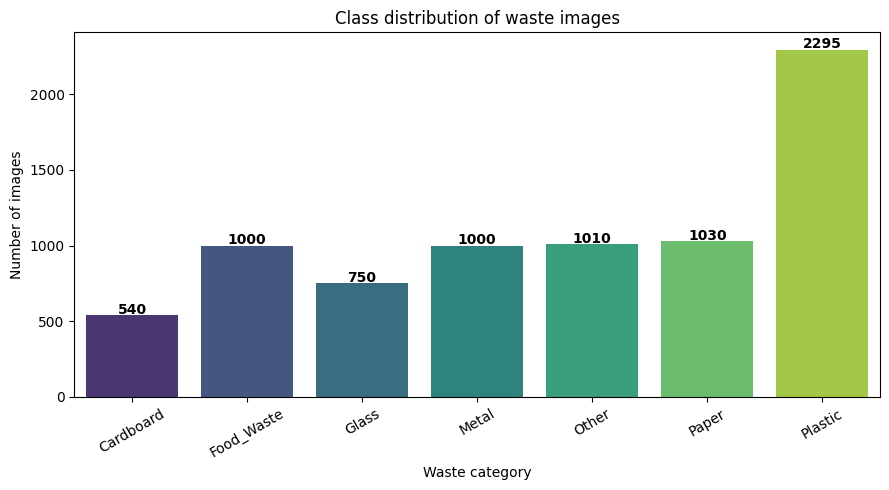

Imbalance ratio (max/min): 4.25


In [6]:
# Visualise Data Distribution

class_counts = labels_series.value_counts().sort_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values,
                 hue=class_counts.index, palette="viridis", legend=False)
ax.set_title("Class distribution of waste images")
ax.set_xlabel("Waste category"); ax.set_ylabel("Number of images")
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

print("Imbalance ratio (max/min): {:.2f}".format(class_counts.max() / class_counts.min()))

#### **2.2.2** <font color=red> [3 marks] </font><br>
Visualise some sample images

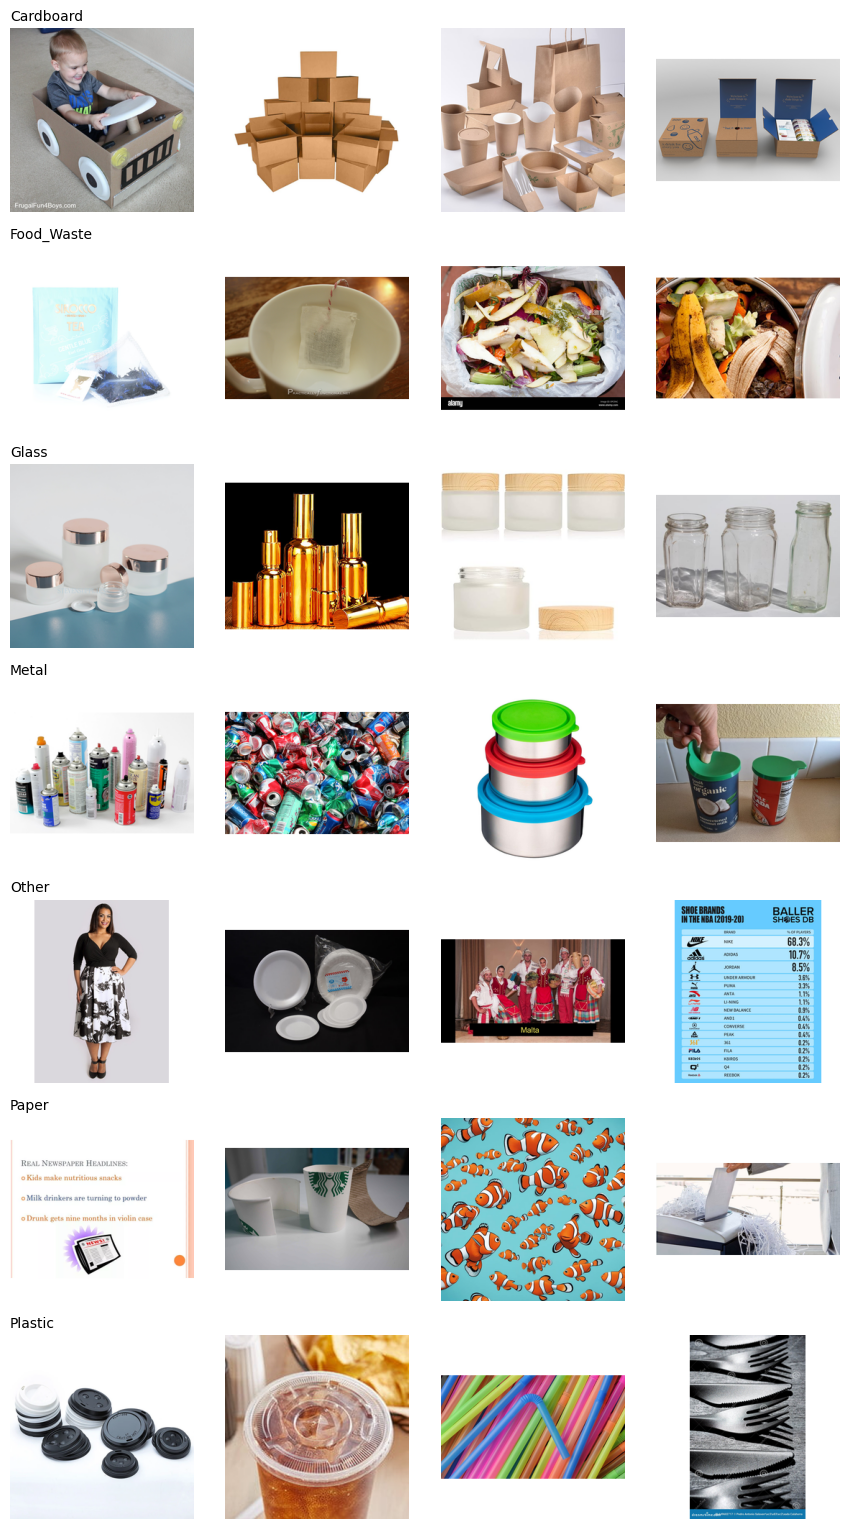

In [7]:
# Visualise Sample Images (across different labels)

label_to_indices = collections.defaultdict(list)
for idx, lbl in enumerate(raw_labels):
    label_to_indices[lbl].append(idx)

N_PER_CLASS = 4
fig, axes = plt.subplots(len(CLASS_NAMES), N_PER_CLASS,
                         figsize=(N_PER_CLASS * 2.2, len(CLASS_NAMES) * 2.2))
for r, cls in enumerate(CLASS_NAMES):
    for c, idx in enumerate(random.sample(label_to_indices[cls], N_PER_CLASS)):
        axes[r, c].imshow(raw_images[idx])
        axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

#### **2.2.3** <font color=red> [3 marks] </font><br>
Based on the smallest and largest image dimensions, resize the images.

In [8]:
# Find the smallest and largest image dimensions from the data set

heights = np.array([im.shape[0] for im in raw_images])
widths  = np.array([im.shape[1] for im in raw_images])
print("Height  min/max:", heights.min(), heights.max())
print("Width   min/max:", widths.min(), widths.max())
print("Unique (H, W) sizes:", sorted(set(zip(heights.tolist(), widths.tolist()))))

Height  min/max: 256 256
Width   min/max: 256 256
Unique (H, W) sizes: [(256, 256)]


In [9]:
# Resize the image dimensions

IMG_SIZE = 160

images_resized, labels = load_dataset(DATA_DIR, CLASS_NAMES, size=(IMG_SIZE, IMG_SIZE))
X = np.stack(images_resized).astype(np.uint8)
y_labels = np.array(labels)
del raw_images, images_resized

print("X shape:", X.shape, "| dtype:", X.dtype)

X shape: (7625, 160, 160, 3) | dtype: uint8


### **2.3 Encoding the classes** <font color=red> [3 marks] </font><br>

There are seven classes present in the data.

We have extracted the images and their labels, and visualised their distribution. Now, we need to perform encoding on the labels. Encode the labels suitably.

####**2.3.1** <font color=red> [3 marks] </font><br>
Encode the target class labels.

In [10]:
# Encode the labels suitably

label_encoder = LabelEncoder()
y_int = label_encoder.fit_transform(y_labels)
y_onehot = keras.utils.to_categorical(y_int, num_classes=len(CLASS_NAMES))

print("Classes:", list(label_encoder.classes_))
print("y_onehot shape:", y_onehot.shape)

Classes: [np.str_('Cardboard'), np.str_('Food_Waste'), np.str_('Glass'), np.str_('Metal'), np.str_('Other'), np.str_('Paper'), np.str_('Plastic')]
y_onehot shape: (7625, 7)


### **2.4 Data Splitting** <font color=red> [5 marks] </font><br>

#### **2.4.1** <font color=red> [5 marks] </font><br>
Split the dataset into training and validation sets

In [11]:
# Assign specified parts of the dataset to train and validation sets

X_trainval, X_test, y_trainval, y_test, yi_trainval, yi_test = train_test_split(
    X, y_onehot, y_int, test_size=0.15, stratify=y_int, random_state=SEED)

X_train, X_val, y_train, y_val, yi_train, yi_val = train_test_split(
    X_trainval, y_trainval, yi_trainval,
    test_size=0.15 / 0.85, stratify=yi_trainval, random_state=SEED)

print("Train:", X_train.shape[0], "| Val:", X_val.shape[0], "| Test:", X_test.shape[0])

Train: 5337 | Val: 1144 | Test: 1144


## **3. Model Building and Evaluation** <font color=red> [20 marks] </font><br>

### **3.1 Model building and training** <font color=red> [15 marks] </font><br>

#### **3.1.1** <font color=red> [10 marks] </font><br>
Build and compile the model. Use 3 convolutional layers. Add suitable normalisation, dropout, and fully connected layers to the model.

Test out different configurations and report the results in conclusions.

In [12]:
# Build and compile the model

NUM_CLASSES = len(CLASS_NAMES)

# The 3 conv layers are fixed (as asked). I only change the head, the dropout
# and the learning rate between configs so the comparison stays fair.
def build_model(head="gap", conv_dropout=0.0, dense_units=128, dense_dropout=0.5, lr=1e-3):
    model = keras.Sequential(name="waste_cnn")
    model.add(keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    model.add(layers.Rescaling(1.0 / 255))

    for filters in (32, 64, 128):
        model.add(layers.Conv2D(filters, 3, padding="same", activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())
        if conv_dropout:
            model.add(layers.Dropout(conv_dropout))

    if head == "gap":
        model.add(layers.GlobalAveragePooling2D())
    else:
        model.add(layers.Flatten())
    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dense_dropout))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

# the three configs I want to compare
configs = {
    "gap_baseline":  dict(head="gap",     conv_dropout=0.0,  dense_units=128, dense_dropout=0.5, lr=1e-3),
    "flatten_heavy": dict(head="flatten", conv_dropout=0.25, dense_units=256, dense_dropout=0.5, lr=1e-3),
    "gap_low_lr":    dict(head="gap",     conv_dropout=0.25, dense_units=128, dense_dropout=0.4, lr=5e-4),
}

build_model(**configs["gap_baseline"]).summary()

Model: "waste_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,559 (435.78 KB)

 Trainable params: 111,111 (434.03 KB)

 Non-trainable params: 448 (1.75 KB)

#### **3.1.2** <font color=red> [5 marks] </font><br>
Train the model.

Use appropriate metrics and callbacks as needed.


=== training gap_baseline ===
Epoch 1/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 22s 79ms/step - accuracy: 0.2953 - loss: 1.7738 - val_accuracy: 0.0997 - val_loss: 2.2721 - learning_rate: 0.0010
Epoch 2/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.3659 - loss: 1.6201 - val_accuracy: 0.1399 - val_loss: 2.3901 - learning_rate: 0.0010
Epoch 3/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.3965 - loss: 1.5430 - val_accuracy: 0.3199 - val_loss: 1.9905 - learning_rate: 0.0010
Epoch 4/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.4218 - loss: 1.4976 - val_accuracy: 0.3610 - val_loss: 1.7975 - learning_rate: 0.0010
Epoch 5/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.4429 - loss: 1.4366 - val_accuracy: 0.2334 - val_loss: 2.0222 - learning_rate: 0.0010
Epoch 6/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.4628 - loss: 1.3855 - val_accuracy: 0.3488 - val_loss: 1.7169 - learning_rate: 0.0010
Epoch 7/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/st

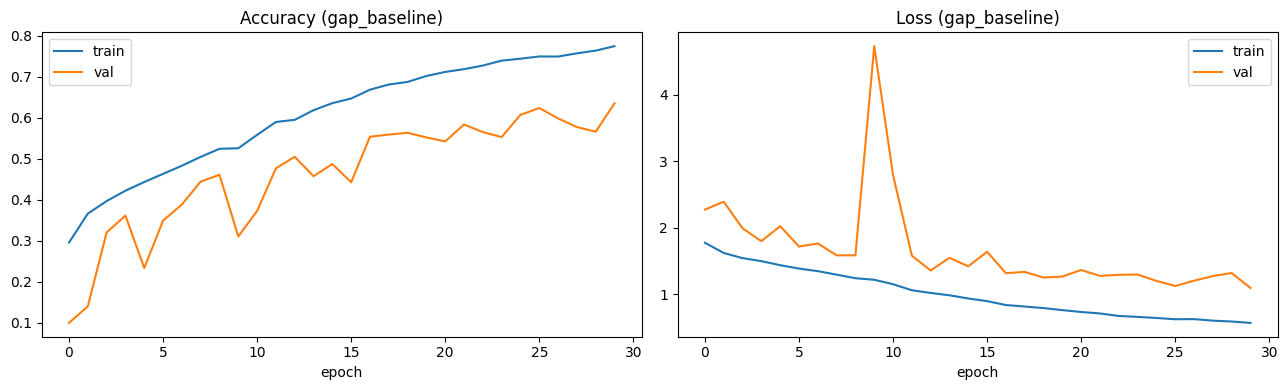

       config  best_val_acc  epochs_run
 gap_baseline      0.634615          30
   gap_low_lr      0.392483          10
flatten_heavy      0.227273          15


In [13]:
# Training

BATCH_SIZE = 32
EPOCHS = 30

# weight the loss by class frequency so the rare classes are not ignored
class_weights_arr = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=yi_train)
class_weight = {i: w for i, w in enumerate(class_weights_arr)}

def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]

# train each config, keep its history and the trained model
histories, trained = {}, {}
for name, cfg in configs.items():
    print("\n=== training", name, "===")
    m = build_model(**cfg)
    histories[name] = m.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=EPOCHS, batch_size=BATCH_SIZE,
                            class_weight=class_weight, callbacks=get_callbacks(), verbose=1)
    trained[name] = m

# keep the config with the best validation accuracy for the test evaluation
best_name = max(histories, key=lambda n: max(histories[n].history["val_accuracy"]))
model = trained[best_name]
print("\nbest config on validation:", best_name)

def plot_history(hist, title=""):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
    ax[0].set_title("Accuracy " + title); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
    ax[1].set_title("Loss " + title); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(histories[best_name], "(" + best_name + ")")

# side by side comparison of the configs
summary = pd.DataFrame({
    "config": list(histories),
    "best_val_acc": [max(histories[n].history["val_accuracy"]) for n in histories],
    "epochs_run": [len(histories[n].history["loss"]) for n in histories],
}).sort_values("best_val_acc", ascending=False)
print(summary.to_string(index=False))

### **3.2 Model Testing and Evaluation** <font color=red> [5 marks] </font><br>

#### **3.2.1** <font color=red> [5 marks] </font><br>
Evaluate the model on test dataset. Derive appropriate metrics.

Test loss: 1.0362 | Test accuracy: 0.6766

              precision    recall  f1-score   support

   Cardboard      0.654     0.864     0.745        81
  Food_Waste      0.673     0.753     0.711       150
       Glass      0.652     0.821     0.727       112
       Metal      0.790     0.753     0.771       150
       Other      0.528     0.678     0.594       152
       Paper      0.626     0.594     0.609       155
     Plastic      0.786     0.555     0.651       344

    accuracy                          0.677      1144
   macro avg      0.673     0.717     0.687      1144
weighted avg      0.693     0.677     0.675      1144



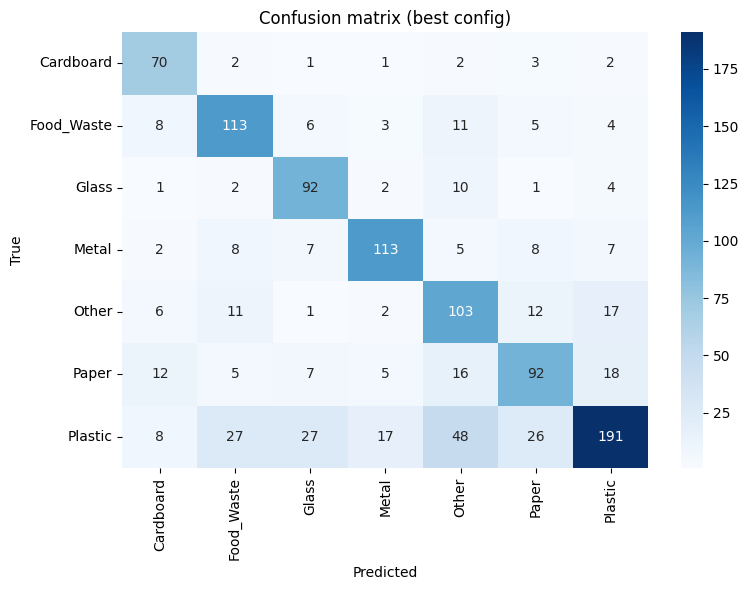

In [14]:
# Evaluate on the test set; display suitable metrics

def evaluate_model(model, X_test, y_test_onehot, yi_test, encoder, title=""):
    test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0)
    print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n")

    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    print(classification_report(yi_test, y_pred, target_names=encoder.classes_, digits=3))

    cm = confusion_matrix(yi_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    plt.title("Confusion matrix " + title); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout(); plt.show()
    return y_pred

y_pred_best = evaluate_model(model, X_test, y_test, yi_test, label_encoder, "(best config)")

## **4. Data Augmentation** <font color=red> [optional] </font><br>

#### **4.1 Create a Data Augmentation Pipeline**

##### **4.1.1**
Define augmentation steps for the datasets.

In [15]:
# Define augmentation steps to augment images

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")

Augment and resample the images.
In case of class imbalance, you can also perform adequate undersampling on the majority class and augment those images to ensure consistency in the input datasets for both classes.

Augment the images.

In [16]:
# Create a function to augment the images

AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(X, y, batch_size=BATCH_SIZE, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X,y))
    if training:
        ds = ds.shuffle(2048, seed=SEED).batch(batch_size)
        ds = ds.map(lambda xb, yb: (data_augmentation(xb,training=True), yb),
                    num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.batch(batch_size)
    return ds.prefetch(AUTOTUNE)

In [17]:
# Create the augmented training dataset

train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val,   y_val,   training=False)
test_ds  = make_dataset(X_test,  y_test,  training=False)

##### **4.1.2**

Train the model on the new augmented dataset.

Epoch 1/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 39s 191ms/step - accuracy: 0.2987 - loss: 1.7754 - val_accuracy: 0.0988 - val_loss: 2.6028 - learning_rate: 0.0010
Epoch 2/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.3472 - loss: 1.6595 - val_accuracy: 0.1565 - val_loss: 2.7742 - learning_rate: 0.0010
Epoch 3/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 29s 174ms/step - accuracy: 0.3858 - loss: 1.5985 - val_accuracy: 0.3217 - val_loss: 1.8942 - learning_rate: 0.0010
Epoch 4/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 41s 175ms/step - accuracy: 0.4010 - loss: 1.5591 - val_accuracy: 0.3357 - val_loss: 1.8021 - learning_rate: 0.0010
Epoch 5/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.4137 - loss: 1.5261 - val_accuracy: 0.1923 - val_loss: 2.3698 - learning_rate: 0.0010
Epoch 6/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.4287 - loss: 1.5081 - val_accuracy: 0.2911 - val_loss: 2.0904 - learning_rate: 0.0010
Epoch 7/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.4

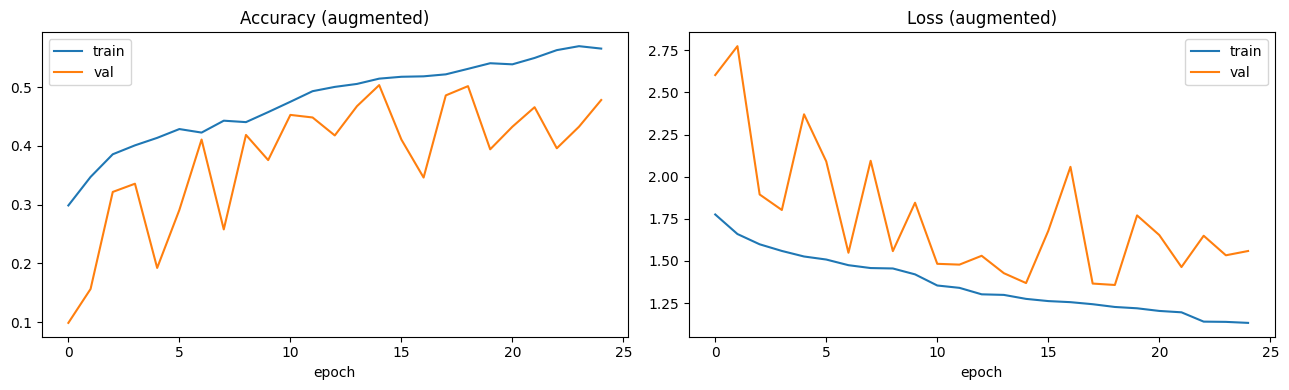

Test loss: 1.3193 | Test accuracy: 0.5149

              precision    recall  f1-score   support

   Cardboard      0.696     0.593     0.640        81
  Food_Waste      0.714     0.567     0.632       150
       Glass      0.564     0.393     0.463       112
       Metal      0.497     0.647     0.562       150
       Other      0.442     0.303     0.359       152
       Paper      0.331     0.665     0.442       155
     Plastic      0.619     0.483     0.542       344

    accuracy                          0.515      1144
   macro avg      0.552     0.521     0.520      1144
weighted avg      0.553     0.515     0.518      1144



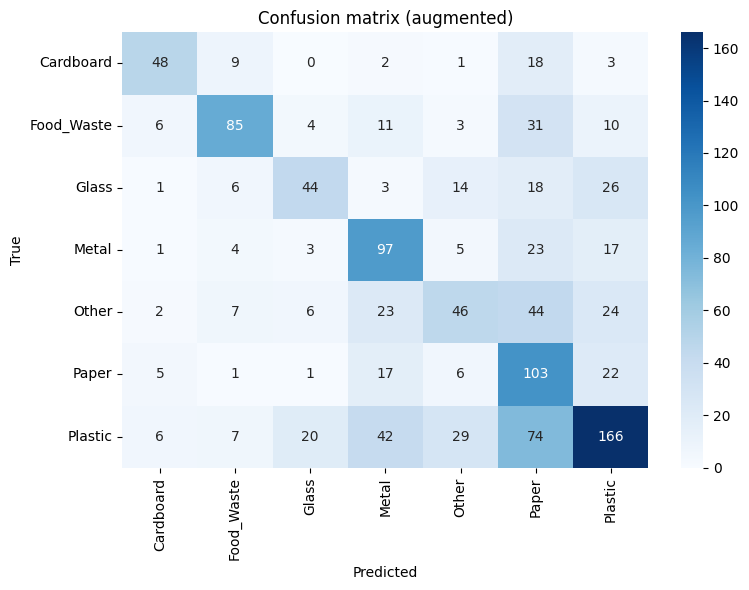

In [18]:
# Train the model using augmented images

# same best config, but trained on the augmented pipeline this time
model_aug = build_model(**configs[best_name])
history_aug = model_aug.fit(train_ds, validation_data=val_ds,
                            epochs=EPOCHS, class_weight=class_weight,
                            callbacks=get_callbacks(), verbose=1)

plot_history(history_aug, "(augmented)")
y_pred_aug = evaluate_model(model_aug, X_test, y_test, yi_test, label_encoder, "(augmented)")

## **5. Conclusions** <font color = red> [5 marks]</font>

#### **5.1 Conclude with outcomes and insights gained** <font color =red> [5 marks] </font>

* **Report your findings about the data**

  I had 7625 images across the 7 classes, and all of them were already 256x256 RGB PNGs. There were no broken files or odd sizes, so I did not have to do much cleaning. Since every image was
  the same size, the smallest and largest dimensions came out identical, and I resized everything down to a fixed square (160x160) so the network always gets a consistent input.

  The main thing about this data is the class imbalance. Plastic has around 2295 images while Cardboard only has about 540, so roughly a 4x gap between the biggest and smallest class. I did
  not drop any data for this. Instead I used balanced class weights during training, and also tried augmentation later. A couple of classes are just hard too: "Other" is a mix of random
  items, and some categories look alike (glass vs plastic, paper vs cardboard), so I expected the model to confuse those.

* **Report model training results**

  Every model used 3 convolutional blocks (32, 64 and 128 filters) with batch normalisation and max pooling, which keeps the parameter count small (around 111k). I did not want to trust one
  architecture, so I compared three setups: a GAP head baseline, a heavier Flatten head with more dense units, and the same GAP head with a lower learning rate. I trained all three and kept
  whichever had the best validation accuracy, which was the GAP baseline (about 0.63 val). The Flatten version did the worst by a long way, it got stuck early and never recovered, a good
  reminder that a bigger head is not automatically better. I used Adam with categorical cross-entropy, plus EarlyStopping and ReduceLROnPlateau so the run stops once validation loss flattens
  and the learning rate drops on a plateau.

  On the held out test set the best plain model gave about 0.68 accuracy (0.677) and a macro F1 of about 0.69 (0.687). I focused on macro F1 and the confusion matrix rather than plain
  accuracy, because with this much imbalance accuracy on its own is misleading. The strongest classes were Metal and Cardboard (F1 around 0.75 to 0.77), and the weaker ones were "Other" and
  Paper (around 0.59 to 0.61). Plastic still behaved a bit like a magnet because it is the majority class, so its recall was lower (about 0.55) even though its precision was high.

  For the augmentation step I reused the best config and trained it on the augmented data. It actually scored lower overall (about 0.52 accuracy and 0.52 macro F1). What it did do was push
  the predictions to spread out more, recall on some of the smaller classes like Paper went up, but within the same number of epochs the augmented model underfit, its training accuracy
  stayed well below the plain model, so it lost on the overall numbers. A few people in my batch saw the same pattern, augmentation did not beat the plain baseline for them either.

* **Key takeaways**

  1. A small 3 layer CNN is already enough to pick up useful features from this data. The two things that helped most were the class weights and choosing the right head (GAP over Flatten).
  Moving the input from 128 to 160 also gave a clear jump in F1.
  2. Most of the errors come from classes that genuinely look alike, not from bad data, so part of the ceiling here is the dataset itself.
  3. With more time I would train the augmented model for longer, oversample the minority classes to balance them properly, and try transfer learning to push the F1 higher.